# CSE475 Task 1: Bonn EEG exploration and related work
Executed on the five user-uploaded archives from https://neurophysicsbonn.de/downloads . No mirror data or synthetic signals used.

**Scope:** raw quality audit across all 500 segments; detailed feature EDA on a fixed stratified development subset of 300 (60/class). Reserve 100 validation and 100 test segments from feature exploration. This is a provisional **segment-level** allocation, not a patient-independent split: patient IDs and parent-recording IDs are absent. No model is trained or evaluated. Do not claim compliance with the course's subject-wise modelling requirement without resolving this limitation.

One row in the feature table is one released EEG segment, not one patient. Group details may be added before submission.

## Team

| Name | Student ID |
|---|---|
| Md. Anwar Nabil Araf | 2023-2-60-242 |
| Jagannath Banik | 2023-2-60-144 |
| Md Naimul Islam Rafi | 2023-2-60-209 |
| Mst Mahabuba Akter Eka | 2023-1-60-134 |

**Submitted to:** Associate Professor Dr. Raihan ul Islam

**Group number:** 02.



In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image,Markdown,HTML
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/manifest.json').exists())
sys.path.insert(0,str(ROOT/'code/task1'))
import eda
meta,records,audit,status=eda.load_inputs(ROOT)
assert len(records)==500
assert set(audit.n_values)=={4097}
display(status)

{'status': 'RAW_AUDITED',
 'manifest_files': 500,
 'parse_failures': 0,
 'nonfinite_values': 0,
 'constant_recordings': 0,
 'duplicate_recordings': 0}

## A. Structure and dataset summary
The official page lists A=Z, B=O, C=N, D=F, E=S and sampling rate 173.61 Hz. Actual files have 4,097 amplitude values each; the page says 4,096, so we preserve all observed samples and record the discrepancy. Nominal N/fs duration is 23.60 s (first-to-last timestamp span is (N-1)/fs). Each segment is one channel. There are 2,048,500 numerical values in total.

The archive metadata entries are excluded; only the genuine TXT signal entries are parsed. No subject IDs are inferred from filenames. Healthy scalp and patient intracranial recordings have different acquisition contexts, so class separation need not reflect seizure status alone.

In [2]:
overview=pd.DataFrame([{'class':k,'meaning':v,'segments':int(audit.label.eq(k).sum()),'values_per_segment':4097,'sampling_rate_hz':173.61,'nominal_duration_s':4097/173.61} for k,v in meta['class_definitions'].items()])
overview.to_csv(ROOT/'outputs/task1/A_dataset_summary.csv',index=False)
display(overview)
print('Signal matrix shape:',(len(records),len(records[0][1])))
print('Patient IDs supplied:',int(audit.subject_id.notna().sum()))
print('Total amplitude values:',int(audit.n_values.sum()))

Signal matrix shape: (500, 4097)
Patient IDs supplied: 0
Total amplitude values: 2048500


,class,meaning,segments,values_per_segment,sampling_rate_hz,nominal_duration_s
0,Z,"A: healthy, eyes open (scalp EEG)",100,4097,173.61,23.598871
1,O,"B: healthy, eyes closed (scalp EEG)",100,4097,173.61,23.598871
2,N,"C: seizure-free, contralateral hippocampal for...",100,4097,173.61,23.598871
3,F,"D: seizure-free, epileptogenic zone (intracran...",100,4097,173.61,23.598871
4,S,E: seizure activity (intracranial),100,4097,173.61,23.598871


## B-C. Raw quality and descriptive statistics
All 500 files are checked for malformed data, missing/nonfinite values, constant signals and exact duplicates. The audit confirms none of these problems. Exact-duplicate absence does not prove statistical independence or absence of near-duplicates.

Detailed EDA uses the 300 development segments. A fixed seed is set before feature inspection. The CSV split column `train` means this provisional development subset; it is not an approved patient-wise training split.

In [3]:
display(audit[['label','n_values','missing_pct','constant','duplicate_signal']].groupby('label').agg({'n_values':['count','min','max'],'missing_pct':'max','constant':'sum','duplicate_signal':'sum'}))
splits=eda.split_sources(ROOT,meta,records,audit)
frame=eda.extract_training(ROOT,meta,records,splits)
assert len(frame)==300 and frame.label.value_counts().eq(60).all()
summary=eda.statistics_quality(ROOT,frame)
display(summary['statistics'])
display(summary['quality'])

Descriptive EDA uses 300 development segments; reserve 100+100. No model trained.
Patient and parent-recording IDs unavailable. This is NOT a verified subject/source-independent split.
split  test  train  validation
label                         
F        20     60          20
N        20     60          20
O        20     60          20
S        20     60          20
Z        20     60          20
                    missing_pct  near_constant_99pct  iqr_outliers
mean                        0.0                False            28
median                      0.0                False            32
std                         0.0                False            50
min                         0.0                False            45
max                         0.0                False            52
q25                         0.0                False            30
q75                         0.0                False            40
skewness                    0.0                False          

n_values             missing_pct constant duplicate_signal
         count   min   max         max      sum              sum
label                                                           
F          100  4097  4097         0.0        0                0
N          100  4097  4097         0.0        0                0
O          100  4097  4097         0.0        0                0
S          100  4097  4097         0.0        0                0
Z          100  4097  4097         0.0        0                0

,count,mean,std,min,25%,50%,75%,max,skewness,excess_kurtosis
mean,300.0,-8.214971,27.638131,-76.350256,-18.937393,-5.312058,6.176593,57.545277,-0.207664,0.542631
median,300.0,-6.010000,44.327263,-160.000000,-25.250000,-5.000000,8.000000,210.000000,1.044300,4.939240
std,300.0,103.002173,118.760817,18.609217,40.406452,54.186814,96.776556,591.033748,2.299697,4.688103
min,300.0,-355.196667,383.438742,-1885.000000,-333.500000,-209.500000,-155.000000,-46.000000,-2.559750,6.428675
max,300.0,330.593333,351.155933,-25.000000,136.000000,194.500000,317.500000,1793.000000,2.055275,3.674250
q25,300.0,-71.956667,72.605740,-364.000000,-93.500000,-47.000000,-27.000000,33.000000,-1.636647,2.562829
q75,300.0,58.673333,88.288596,-63.000000,14.000000,33.000000,64.250000,406.000000,2.130093,4.475434
skewness,300.0,-0.022814,0.488826,-1.580637,-0.165335,-0.022661,0.114529,2.662088,1.520116,8.902239
excess_kurtosis,300.0,0.532387,1.245134,-1.042345,0.026171,0.285571,0.598699,10.871783,5.018357,31.686945
rms,300.0,108.910307,116.933630,19.754942,46.049416,64.428502,103.385310,590.986677,2.301600,4.747177


,missing_pct,near_constant_99pct,iqr_outliers
mean,0.0,False,28
median,0.0,False,32
std,0.0,False,50
min,0.0,False,45
max,0.0,False,52
q25,0.0,False,30
q75,0.0,False,40
skewness,0.0,False,43
excess_kurtosis,0.0,False,28
rms,0.0,False,48


### Feature definitions
Thirteen time-domain descriptors: mean, median, sample std, min, max, q25, q75, skewness, excess kurtosis, RMS, peak-to-peak, average absolute first difference, and zero-crossing fraction. Six spectral descriptors: normalized PSD entropy and relative delta/theta/alpha/beta/gamma PSD-bin masses. Welch uses nperseg=256 and fs=173.61 Hz. Bands are [0.5,4), [4,8), [8,13), [13,30), [30,45) Hz. No extra filtering, amplitude normalization, interpolation, or resampling is applied to raw EDA.

The site specifies acquisition bandwidth 0.5-85 Hz and says the manuscript's 40-Hz low-pass filter was not applied to downloads. Consequently gamma here means 30-45 Hz on the supplied signals, not on a 40-Hz-filtered reconstruction. Relative power is discrete PSD-bin mass / total PSD-bin mass.

There are no missing engineered values or near-constant features (99% modal-value criterion). Pooled 1.5-IQR thresholds flag **557 feature-record entries across 132 segments**, not 557 corrupt recordings. These extremes may be real class structure; retain them and inspect raw traces.

## D. Class balance; E-H. Distributions, correlation, PCA and interaction
Each original class has 100 segments; each development class has 60. No rebalancing is needed for this five-class task. A later seizure/nonseizure collapse would be 100 versus 400 and needs a different imbalance discussion. Macro-F1 and class recall remain appropriate for later evaluation.

Development files analyzed: 300; class counts: {'F': 60, 'N': 60, 'O': 60, 'S': 60, 'Z': 60}.

Class balance: use macro-F1 and class recall; observed counts describe this training partition only.

Near-constant features: []. Review before selecting features; fit any selector on development only.

Feature outlier flags: 557. Inspect original traces; do not remove seizure-related extremes automatically.

First two PCs explain 59.2% of standardized training variance. Visual separation is not evidence of held-out predictive performance.

Review histograms/boxplots/violins for overlap before stating which classes separate; inspect interactive point IDs to trace unusual records.

Frequency bands above Nyquist are marked missing, not invented. Unavailable features are excluded from PCA and listed in its metadata.
Interactive file: outputs/task1/H_pca_interactive.html
Interactive file: outputs/task1/H_rms_interactive.html


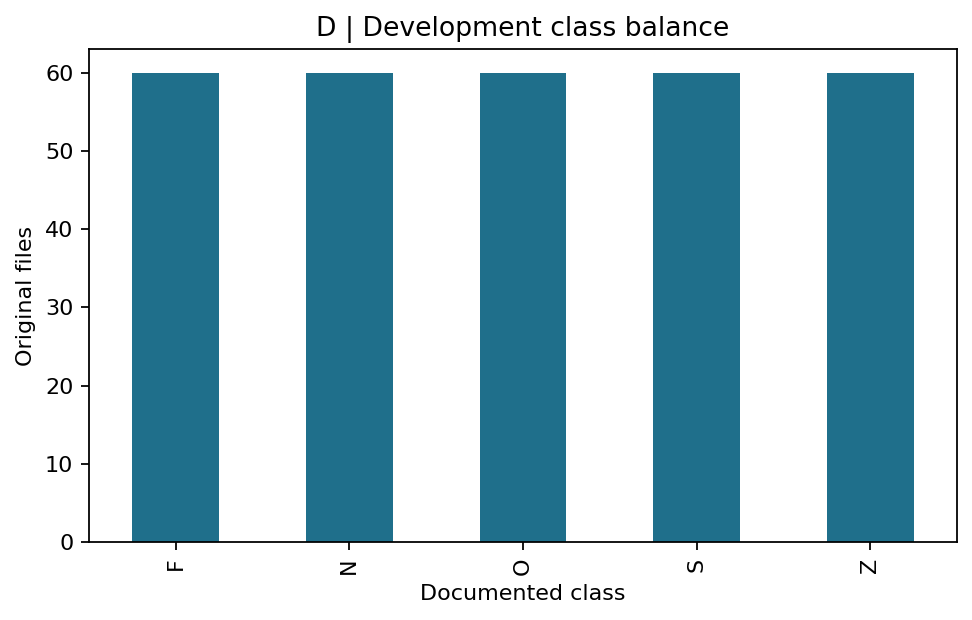

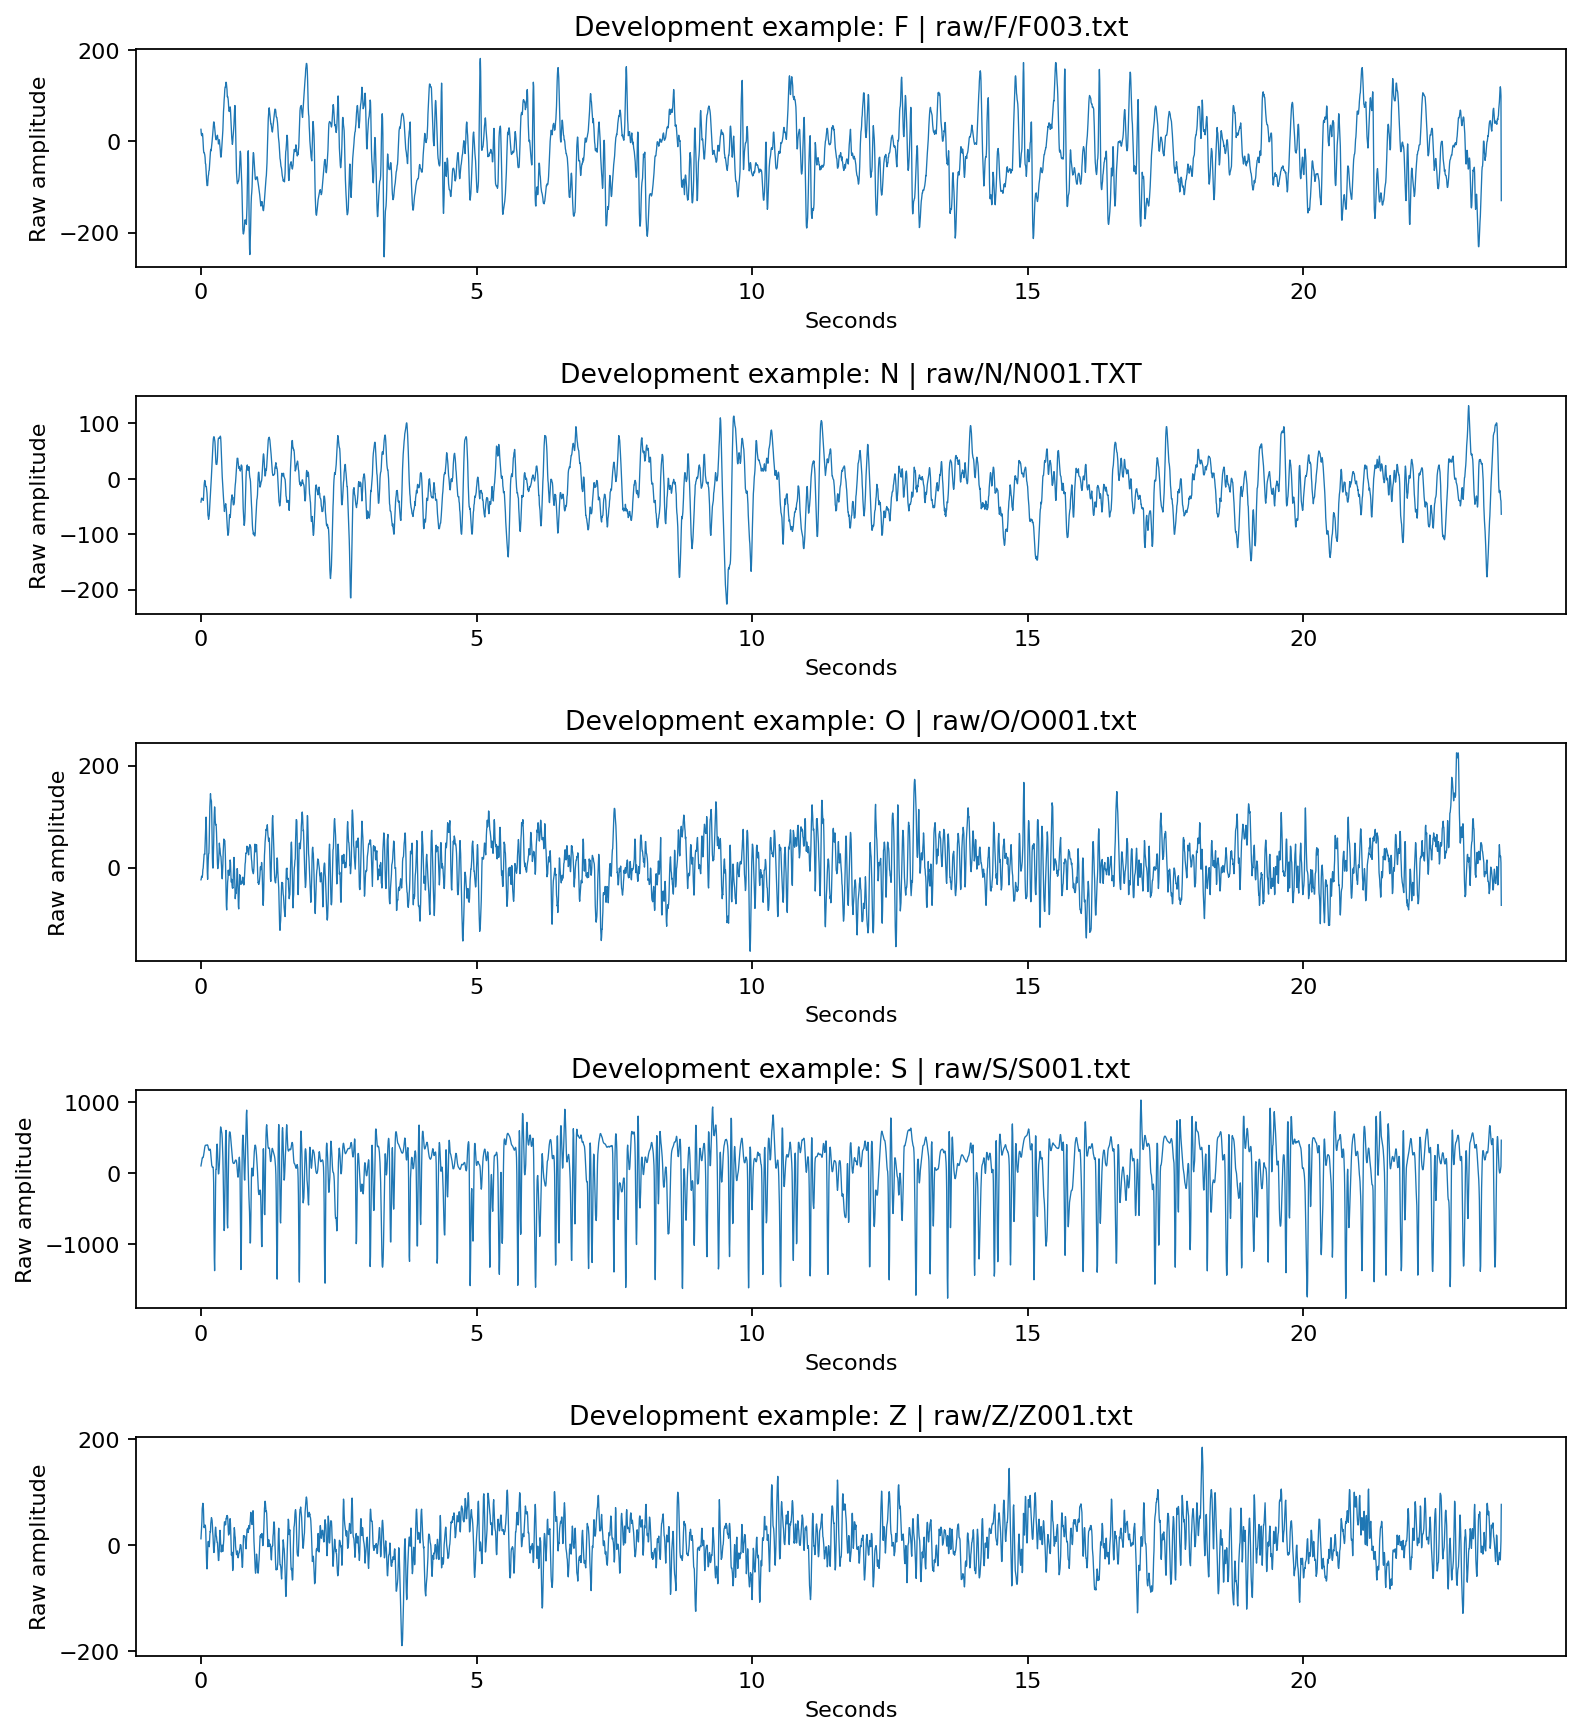

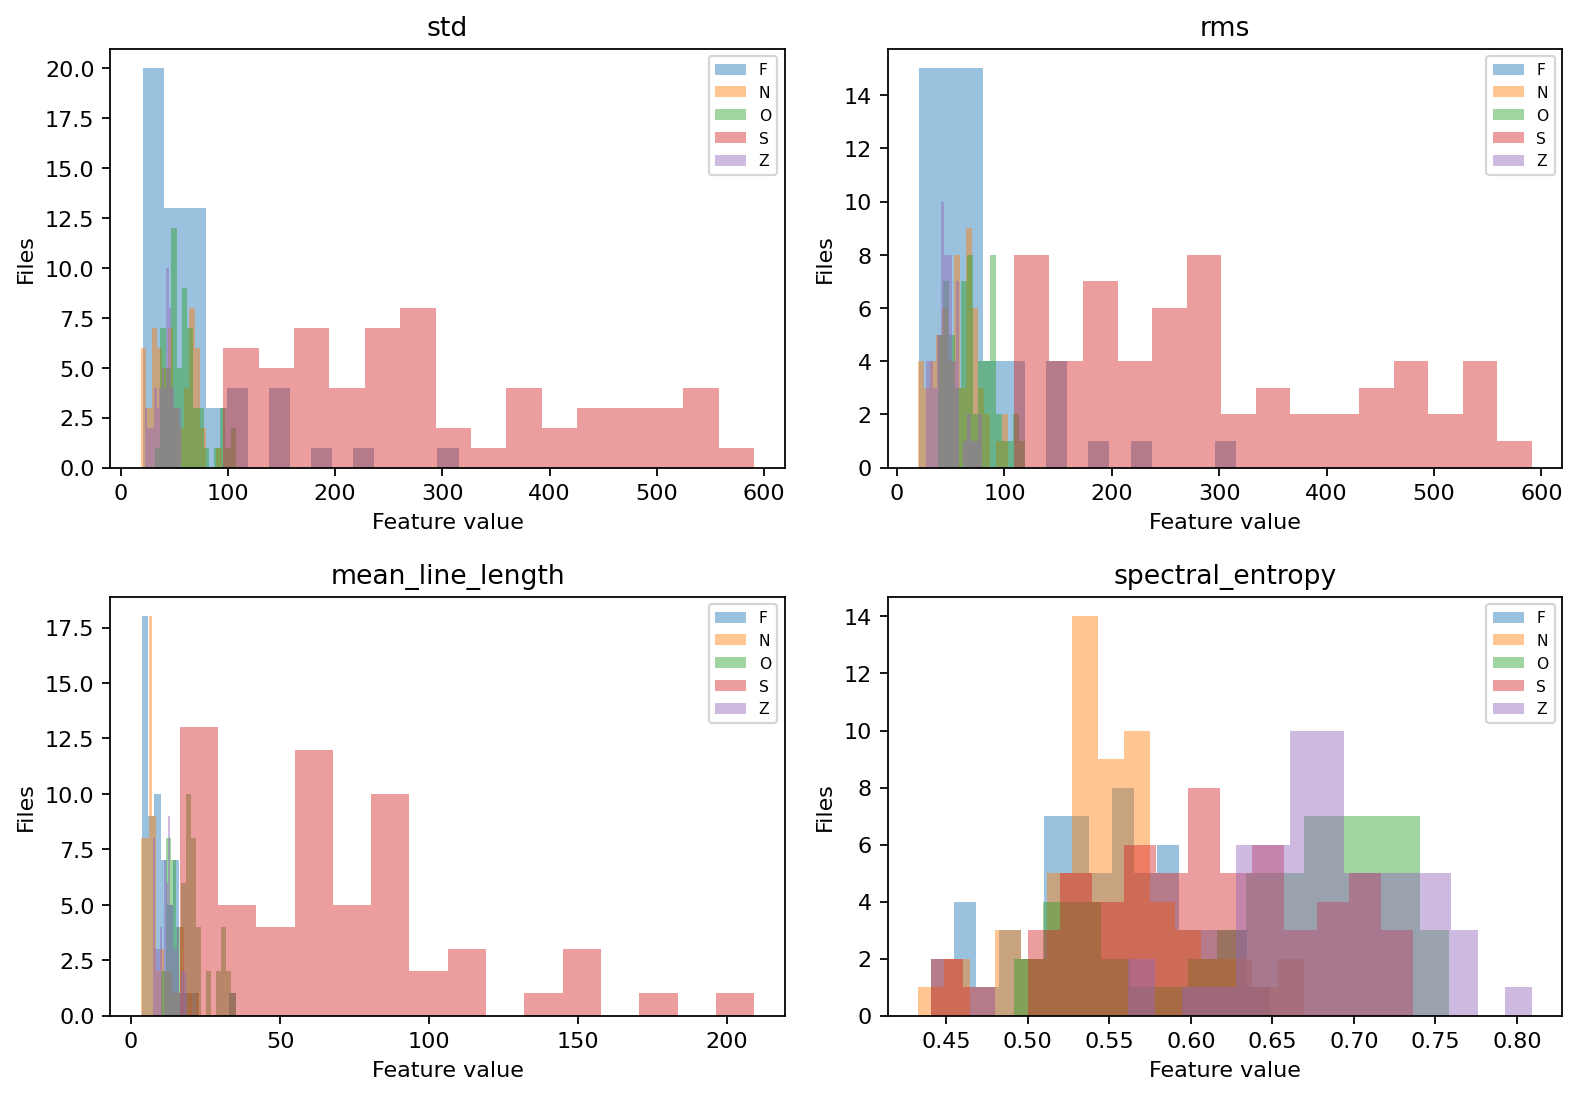

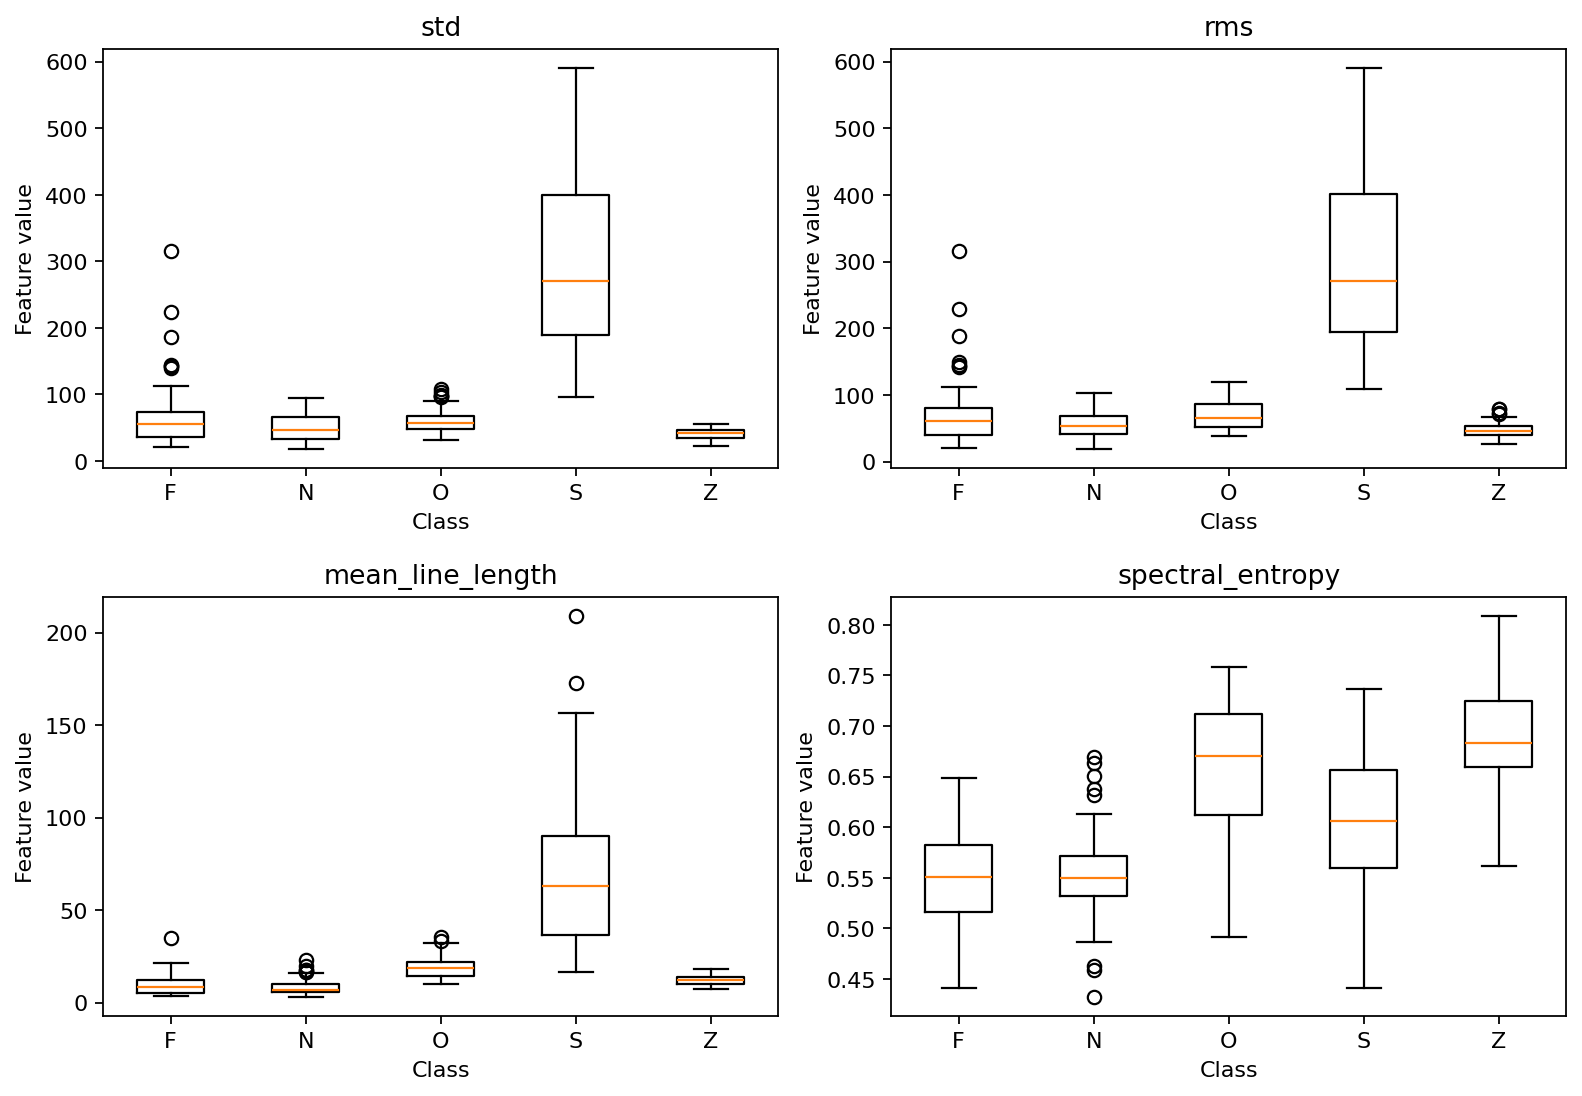

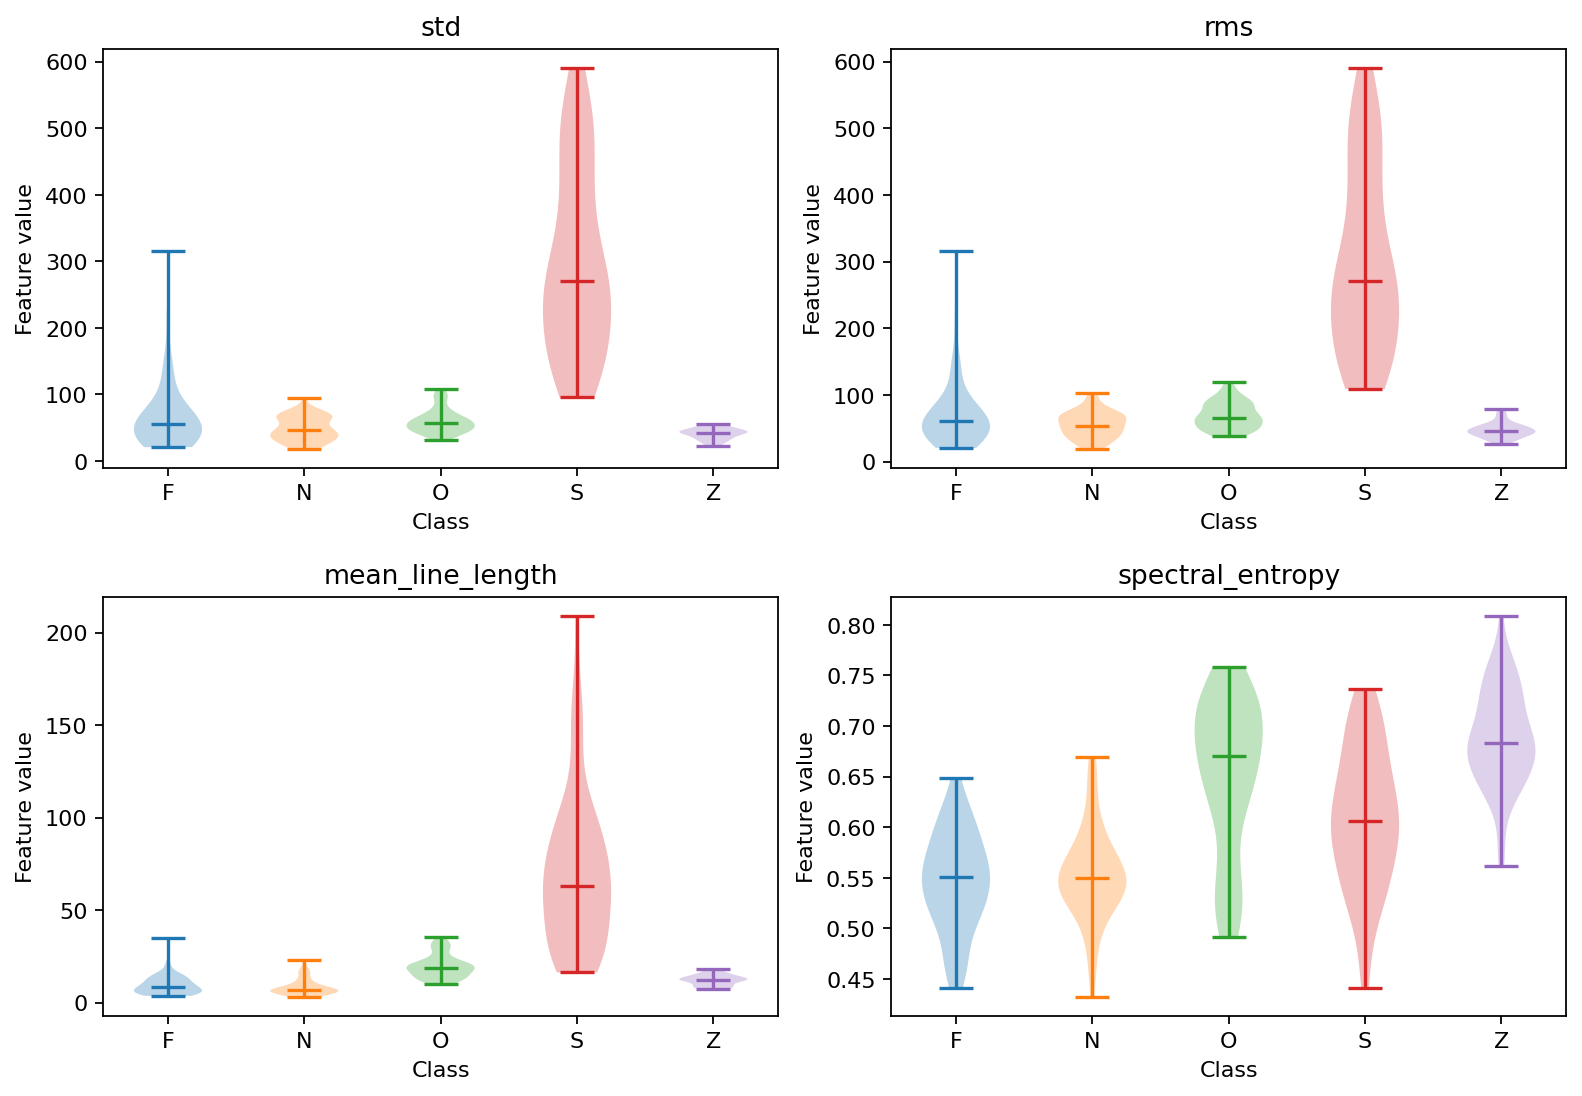

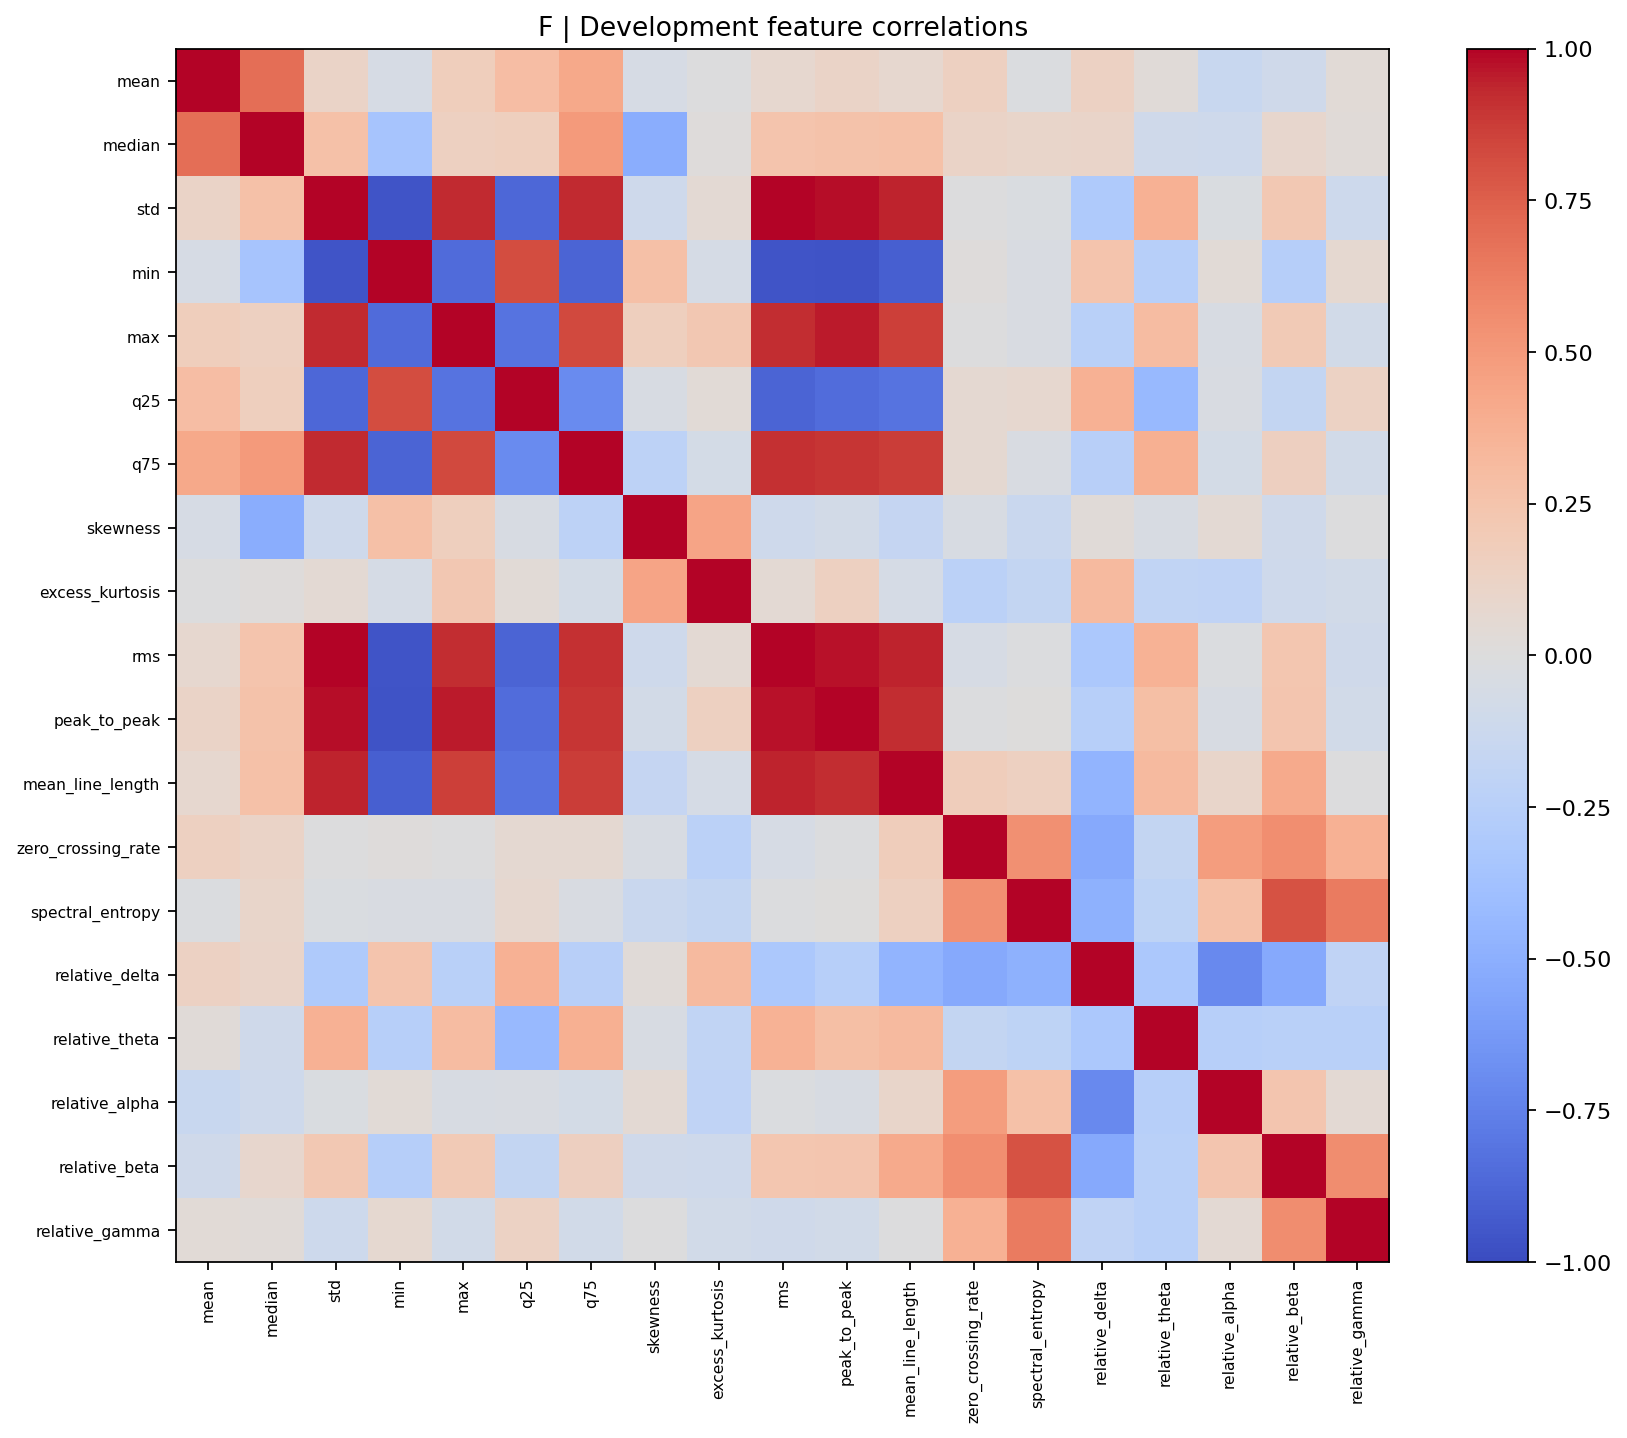

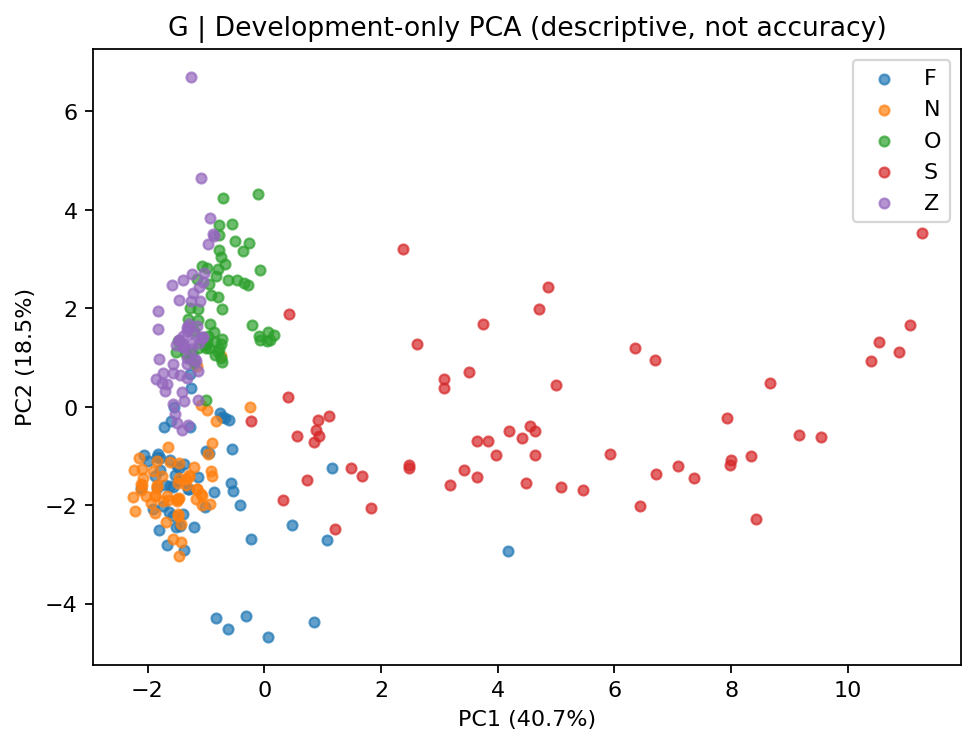

,rms,std,mean_line_length,spectral_entropy,relative_alpha
label,,,,,
F,60.6681,55.7346,8.3413,0.5506,0.0863
N,54.2044,46.1878,6.8116,0.5498,0.0675
O,65.9967,57.1816,18.8136,0.6703,0.4307
S,271.4267,270.5529,62.7814,0.6058,0.1628
Z,46.0001,42.5737,12.3838,0.6836,0.2413


In [4]:
plot_paths=eda.plots(ROOT,meta,records,splits,frame,summary)
for path in plot_paths:
    if path.suffix=='.png':display(Image(filename=str(path)))
    else:print('Interactive file:',path.relative_to(ROOT))
display(frame.groupby('label')[['rms','std','mean_line_length','spectral_entropy','relative_alpha']].median().round(4))

### Interpretation of plots
- **Waveforms:** representative traces show differing amplitudes and oscillation patterns. Examples illustrate individual segments, not entire populations; all use documented seconds on the x-axis.
- **Histograms/boxplots:** S has median RMS 271.43, compared with 46.00-66.00 in the other four classes. High F values overlap the S range. Mean line length is also higher for S (median 62.78). No single threshold is justified by this EDA.
- **Violins:** F and N overlap strongly in spectral entropy (medians 0.5506 and 0.5498); O and Z also overlap (0.6703 and 0.6836). Similar summaries do not imply identical signals.
- **Frequency features:** O has median relative alpha mass 0.431, versus Z 0.241. N and F have median relative delta masses 0.621 and 0.610. These are descriptive associations, not causal or clinical claims.
- **Correlations:** seven pairs exceed |r|=0.95. RMS versus std is r=0.99594; they provide nearly redundant amplitude information. Compare a reduced feature set in later training; fit selection within each training fold.
- **PCA:** PC1=40.71%, PC2=18.48%, total=59.19%; PC3 adds 11.80%. S tends towards higher PC1, F/N largely overlap, and O/Z overlap. PCA is unsupervised and provides no held-out accuracy estimate.
- **Preprocessing consequence:** preserve raw amplitudes for audit; later fit scaling only on training data. Review outliers rather than removing them automatically. Avoid treating scalp/intracranial differences as proof of general seizure detection.

## H. Interactive exploration
Open the following HTML outputs locally after extracting the package. They contain their JavaScript and work offline. Hover shows the file ID; legend clicks hide/show classes; zoom reveals overlap. Use them to connect unusual feature values to raw signals.

In [5]:
for name in ['H_pca_interactive.html','H_rms_interactive.html','H_pca_3d.html']:
    path=ROOT/'outputs/task1'/name
    assert path.exists()
    display(HTML(f'<a href="../../outputs/task1/{name}">{name}</a>'))
# In Jupyter, uncomment to embed a view directly:
# display(HTML((ROOT/'outputs/task1/H_pca_interactive.html').read_text()))

## Related-work table (five EEG/GNN studies)
The table includes title, authors, year, dataset, application, model/GNN, graph construction, split, metrics, strengths, limitations, gap and relation. R5 is explicitly abstract-level because the full chapter is subscription content. Published scores are not our results and are not directly comparable across datasets/splits.

In [6]:
papers=json.loads((ROOT/'related_work/papers.json').read_text())
for paper in papers:
    display(Markdown('### '+paper['id']+' - '+paper['title']))
    display(pd.DataFrame({'Field':list(paper),'Review':list(paper.values())}))

### R1 - Self-Supervised Learning for Anomalous Channel Detection in EEG Graphs: Application to Seizure Analysis

,Field,Review
0,id,R1
1,title,Self-Supervised Learning for Anomalous Channel...
2,authors,Thi Kieu Khanh Ho; Narges Armanfard
3,year,2023 (AAAI; preprint 2022)
4,dataset,"TUSZ v1.5.2, 19 channels"
5,area,Seizure clip and channel detection
6,model,"EEG-CGS: GCN autoencoder, contrastive and reco..."
7,graph,"Electrodes are nodes; distance, random, correl..."
8,split,"Normal-only training: 35,019 clips; held-out t..."
9,metrics,"Combined graphs: clip F1 0.534, sensitivity 0...."


### R2 - Dynamic GNNs for Precise Seizure Detection and Classification from EEG Data

,Field,Review
0,id,R2
1,title,Dynamic GNNs for Precise Seizure Detection and...
2,authors,Arash Hajisafi; Haowen Lin; Yao-Yi Chiang; Cyr...
3,year,2024 (arXiv version reviewed)
4,dataset,TUSZ v1.5.2
5,area,Seizure detection and type classification
6,model,"NeuroGNN: modified residual GCN, BiGRU and hie..."
7,graph,Electrodes and brain-region meta-nodes; tempor...
8,split,Separate test set; training portion divided 9:...
9,metrics,With pretraining: detection AUROC 0.876 +/- 0....


### R3 - Sequential graph convolutional network and DeepRNN based hybrid framework for epileptic seizure detection from EEG signal

,Field,Review
0,id,R3
1,title,Sequential graph convolutional network and Dee...
2,authors,Ferdaus Anam Jibon; A. R. Jamil Chowdhury; Mah...
3,year,2024
4,dataset,CHB-MIT and TUH
5,area,Seizure detection
6,model,Sequential GCN plus DeepRNN
7,graph,Pearson-correlation graph; periodogram-based s...
8,split,CHB-MIT patient-by-patient experiments: 5-fold...
9,metrics,Table 2 accuracy: CHB-MIT 99.007%; TUH 98.08%.


### R4 - Multi-branch fusion graph neural network based on multi-head attention for childhood seizure detection

,Field,Review
0,id,R4
1,title,Multi-branch fusion graph neural network based...
2,authors,Yang Li; Yang Yang; Shangling Song; Hongjun Wa...
3,year,2024
4,dataset,CHB-MIT
5,area,Childhood seizure detection
6,model,MGCNA: multi-branch GCN with multi-head attention
7,graph,"Spatial-distance, functional-correlation and t..."
8,split,Patient-specific 5-fold CV; patient-independen...
9,metrics,"Table 1: patient-specific accuracy 99.32%, F1 ..."


### R5 - Lightweight Graph Neural Network Framework for Seizure Detection Using Single-Channel EEG

,Field,Review
0,id,R5
1,title,Lightweight Graph Neural Network Framework for...
2,authors,Shobha Sharma; Tapan Kumar Gandhi
3,year,2026 (online 17 April; PReMI 2025 proceedings)
4,dataset,"Bonn, five categories Z/N/F/S/O"
5,area,EEG segment classification
6,model,Lightweight GCN
7,graph,Eight non-overlapping temporal segments per re...
8,split,Ten random seeds; split proportions and subjec...
9,metrics,Across seeds: accuracy 0.87 +/- 0.0147; macro-...


## Research gap and proposed experiment
**Question:** On a fixed, transparently documented segment-level Bonn partition, does adding temporal-neighbour edges to feature-similarity edges improve macro-F1 over temporal-only and similarity-only GCNs, with the same features and training budget?

This is a controlled extension, not a claim that Bonn GNNs are new. Sharma and Gandhi (2026) already use eight temporal parts and similarity edges. Their accessible abstract does not isolate the value of temporal edges. Confirm the full chapter before claiming a previously untested contribution.

Proposed Task 2 graph: one released segment per graph; eight contiguous non-overlapping parts as nodes using numpy.array_split (513 + seven times 512 values); 19 per-node features; undirected temporal links, k-nearest feature-similarity links, or their union. Standardization fits on training nodes only, k is selected on validation only, and every edge stays inside its segment. These are temporal graphs, not anatomical connectivity. Compare matched baselines and report cost, class-wise metrics and fold variability.

**Evaluation limit:** Segment separation is not patient or parent-recording separation. No supplied metadata resolves that. The modelling protocol must be agreed with the instructor before claims of course-compliant subject-wise evaluation. This does not prevent honest descriptive Task 1 EDA.

## References
Dataset: Andrzejak RG, Lehnertz K, Mormann F, Rieke C, David P, Elger CE (2001). *Indications of nonlinear deterministic and finite-dimensional structures in time series of brain electrical activity: Dependence on recording region and brain state*. Physical Review E 64, 061907. https://doi.org/10.1103/PhysRevE.64.061907 . Download page: https://neurophysicsbonn.de/downloads . The 2001 dataset citation is additional to the five recent GNN papers. Paper URLs are in the table and PDF.

In [7]:
completion={'raw_segments_audited':500,'development_segments_explored':300,'reserved_segments':200,'features':19,'eda_A_to_H_executed':True,'five_paper_table':True,'research_question':True,'model_trained':False,'patient_independence_verified':False}
(ROOT/'outputs/task1/completion.json').write_text(json.dumps(completion,indent=2))
display(completion)

{'raw_segments_audited': 500,
 'development_segments_explored': 300,
 'reserved_segments': 200,
 'features': 19,
 'eda_A_to_H_executed': True,
 'five_paper_table': True,
 'research_question': True,
 'model_trained': False,
 'patient_independence_verified': False}